<a href="https://colab.research.google.com/github/Venus686/Mineria-de-datos/blob/main/Pr%C3%A1ctica3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**NOTAS**
train_test_split, random_state shuffle(mezclar los datos antes de dividirlo), para el train y test(20%)
DecisionTreeClassifier, predict
RandomOverSampling o undersampling

PRECISION_SCORE, recall y f1_score, metrics, confusiob_matrix


In [34]:
import pandas as pd
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score,roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay


dataset= pd.read_csv('/content/Telco-Customer-Churn.csv')

numericas = ["tenure", "MonthlyCharges", "TotalCharges"]

categoricas = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService",
               "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
               "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
               "Contract", "PaperlessBilling", "PaymentMethod"]

servicios = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
             "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
X = dataset.drop(columns=['Churn'])
y= (dataset['Churn']== "Yes").astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42, stratify=y )



In [35]:
class ConvertirNumerico(BaseEstimator, TransformerMixin):
    def __init__(self, columna):
        self.columna = columna

    def fit(self, X, y=None):
        self.is_fitted_ = True
        return self

    def transform(self, X):
        X = X.copy()
        X[self.columna] = pd.to_numeric(
            X[self.columna], errors="coerce").fillna(0)
        return X

class NumServicios(TransformerMixin, BaseEstimator):
    def __init__(self, servicios=None):
        self.servicios = servicios
    def fit(self, X, y=None):
        self.is_fitted_ = True
        return self
    def transform(self, X):
        X = X.copy()
        X["num_services"] = (X[self.servicios] == "Yes").sum(axis=1)
        return X

class MyTransformer(TransformerMixin, BaseEstimator):
    def fit(self, dataset, y=None):
        return self
    def transform(self, dataset):
        X = dataset.copy()
        tenure = np.maximum(X["tenure"], 1)
        X["avg_monthly_charge"] = X["TotalCharges"] / tenure
        return X

numericas_final = numericas + ["num_services", "avg_monthly_charge"]

preprocesado = ColumnTransformer([
    ("numericas", StandardScaler(), numericas_final),
    ("categoricas", Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), categoricas),
])

pipeline10 = Pipeline([
    ("convertir",     ConvertirNumerico("TotalCharges")),
    ("n_servicios",   NumServicios(servicios=servicios)),
    ("gasto_medio",   MyTransformer()),
    ("preprocesado",  preprocesado),
])

salida = pipeline10.fit_transform(dataset)
columnas = pipeline10.named_steps["preprocesado"].get_feature_names_out()
salida_df = pd.DataFrame(salida, columns=columnas, index=dataset.index)
salida_df.head()

,numericas__tenure,numericas__MonthlyCharges,numericas__TotalCharges,numericas__num_services,numericas__avg_monthly_charge,categoricas__gender_Female,categoricas__gender_Male,categoricas__SeniorCitizen_0,categoricas__SeniorCitizen_1,categoricas__Partner_No,...,categoricas__StreamingMovies_Yes,categoricas__Contract_Month-to-month,categoricas__Contract_One year,categoricas__Contract_Two year,categoricas__PaperlessBilling_No,categoricas__PaperlessBilling_Yes,categoricas__PaymentMethod_Bank transfer (automatic),categoricas__PaymentMethod_Credit card (automatic),categoricas__PaymentMethod_Electronic check,categoricas__PaymentMethod_Mailed check
0,-1.277445,-1.160323,-0.992611,-1.145997,-1.151302,1.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,0.066327,-0.259629,-0.172165,-0.176011,-0.301458,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,-1.236724,-0.362660,-0.958066,-0.176011,-0.350966,0.0,1.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0.514251,-0.746535,-0.193672,-0.176011,-0.786053,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,-1.236724,0.197365,-0.938874,-1.145997,0.367602,1.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [46]:
modelo_arbol = Pipeline([
    ("preprocesamiento", pipeline10),
    ("clasificador", DecisionTreeClassifier(max_depth=6, min_samples_leaf=60,
                                            class_weight="balanced", random_state=42)),
])
modelo_arbol.fit(X_train, y_train)
preddiction= modelo_arbol.predict(X_test)
print(f1_score(y_test, preddiction))

0.6305525460455038


In [37]:
modelo_rf = Pipeline([
    ("preprocesamiento", pipeline10),
    ("clasificador", RandomForestClassifier(n_estimators=600, max_depth=10, min_samples_leaf=5,
                                            class_weight="balanced", random_state=42)),
])
modelo_rf.fit(X_train, y_train)
preddiction = modelo_rf.predict(X_test)
print(f1_score(y_test, preddiction))

0.6314606741573033


In [49]:
from imblearn.pipeline import Pipeline as ImbPipeline
modelo_gb = ImbPipeline(pipeline10.steps + [
    ("muestreo", RandomOverSampler(random_state=42)),
    ("clasificador", GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3,
                                                min_samples_leaf=20,random_state=42)),
])
modelo_gb.fit(X_train, y_train)
preddiction = modelo_gb.predict(X_test)
print(f1_score(y_test, preddiction))

0.6350210970464135


# Comparación de algoritmos
### 6. Toma la mejor configuración encontrada para cada algoritmo y compara, como mínimo,los tres entre sí. Comenta los resultados y justifica tu análisis con detalle.


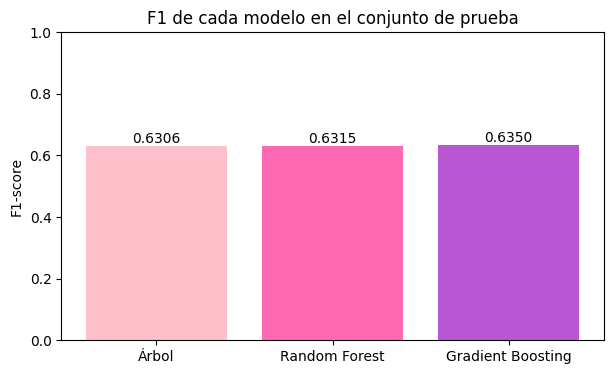

In [44]:
nombres = ["Árbol", "Random Forest", "Gradient Boosting"]
f1s = [f1_score(y_test, modelo_arbol.predict(X_test)),
       f1_score(y_test, modelo_rf.predict(X_test)),
       f1_score(y_test, modelo_gb.predict(X_test))]

plt.figure(figsize=(7, 4))
barras = plt.bar(nombres, f1s, color=["pink", "hotpink", "mediumorchid"])
plt.bar_label(barras, fmt="%.4f")
plt.ylim(0, 1)
plt.ylabel("F1-score")
plt.title("F1 de cada modelo en el conjunto de prueba")
plt.show()

Los 3 modelos, tienen un resultado de f1 muy igualado. El árbol y random forest, apenas se sobreajustan porque tienen una profundidad límite, y el bosque no tiene mucho que corregir.

Como podemos observar el gradient boosting es un poco mejor, ya que construye los árboles uno tras otro, y corrige los errores del anterior, por lo q gradient boosting va a tener un rendimiento un poco mejor.

### 7. Calcula para cada modelo las siguientes métricas, sobre el conjunto de prueba:
• Matriz de confusión.

• Precisión, exhaustividad (recall) y F1-score.

• Área bajo la curva ROC (AUC-ROC).

Asegúrate de entender qué mide cada una antes de decidir qué algoritmo predice mejor

In [40]:
modelos = {"Árbol": modelo_arbol, "Random Forest": modelo_rf, "Gradient Boosting": modelo_gb}

resultados = []
for nombre, modelo in modelos.items():
    pred = modelo.predict(X_test)
    prob = modelo.predict_proba(X_test)[:, 1]
    print(nombre)
    print(confusion_matrix(y_test, pred))
    resultados.append({"modelo": nombre,
                       "precision": precision_score(y_test, pred),
                       "recall": recall_score(y_test, pred),
                       "f1": f1_score(y_test, pred),
                       "auc": roc_auc_score(y_test, prob)})

resultados = pd.DataFrame(resultados).set_index("modelo").round(3)
resultados

Árbol
[[777 258]
 [ 83 291]]
Random Forest
[[800 235]
 [ 93 281]]
Gradient Boosting
[[762 273]
 [ 73 301]]


,precision,recall,f1,auc
modelo,,,,
Árbol,0.530,0.778,0.631,0.835
Random Forest,0.545,0.751,0.631,0.842
Gradient Boosting,0.524,0.805,0.635,0.844


In [41]:
pred_arbol = modelo_arbol.predict(X_test)
prob_arbol = modelo_arbol.predict_proba(X_test)[:, 1]
print("Árbol")
print(confusion_matrix(y_test, pred_arbol))

pred_rf = modelo_rf.predict(X_test)
prob_rf = modelo_rf.predict_proba(X_test)[:, 1]
print("Random Forest")
print(confusion_matrix(y_test, pred_rf))

pred_gb = modelo_gb.predict(X_test)
prob_gb = modelo_gb.predict_proba(X_test)[:, 1]
print("Gradient Boosting")
print(confusion_matrix(y_test, pred_gb))

resultados = pd.DataFrame({
    "precision": [precision_score(y_test, pred_arbol), precision_score(y_test, pred_rf), precision_score(y_test, pred_gb)],
    "recall":    [recall_score(y_test, pred_arbol),    recall_score(y_test, pred_rf),    recall_score(y_test, pred_gb)],
    "f1":        [f1_score(y_test, pred_arbol),        f1_score(y_test, pred_rf),        f1_score(y_test, pred_gb)],
    "auc":       [roc_auc_score(y_test, prob_arbol),   roc_auc_score(y_test, prob_rf),   roc_auc_score(y_test, prob_gb)],
}, index=["Árbol", "Random Forest", "Gradient Boosting"]).round(3)

resultados

Árbol
[[777 258]
 [ 83 291]]
Random Forest
[[800 235]
 [ 93 281]]
Gradient Boosting
[[762 273]
 [ 73 301]]


,precision,recall,f1,auc
Árbol,0.530,0.778,0.631,0.835
Random Forest,0.545,0.751,0.631,0.842
Gradient Boosting,0.524,0.805,0.635,0.844


### 8. Crea gráficas con los resultados de las métricas para cada algoritmo. Úsalas para justificar los cambios que introduces en los parámetros.


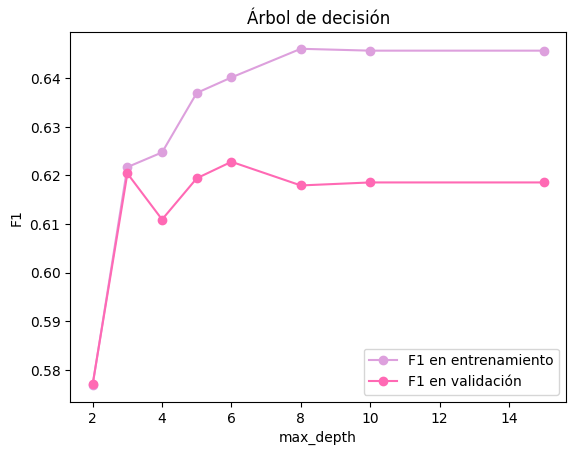

   max_depth  train  validacion
0          2  0.577       0.577
1          3  0.622       0.620
2          4  0.625       0.611
3          5  0.637       0.619
4          6  0.640       0.623
5          8  0.646       0.618
6         10  0.646       0.619
7         15  0.646       0.619


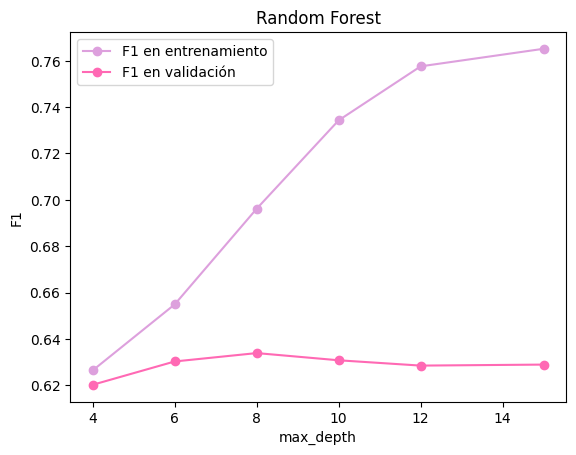

   max_depth  train  validacion
0          4  0.626       0.620
1          6  0.655       0.630
2          8  0.696       0.634
3         10  0.734       0.631
4         12  0.758       0.628
5         15  0.765       0.629


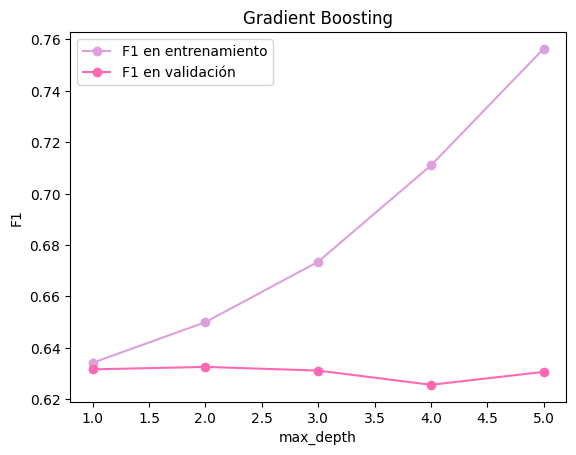

   max_depth  train  validacion
0          1  0.634       0.632
1          2  0.650       0.633
2          3  0.674       0.631
3          4  0.711       0.626
4          5  0.756       0.631


In [50]:
from sklearn.model_selection import cross_validate

def curva_profundidad(modelo, profundidades, titulo):
    f1_train, f1_validacion = [], []
    for d in profundidades:
        modelo.set_params(clasificador__max_depth=d)
        cv = cross_validate(modelo, X_train, y_train, cv=5, scoring="f1",
                            return_train_score=True, n_jobs=-1)
        f1_train.append(cv["train_score"].mean())
        f1_validacion.append(cv["test_score"].mean())
    plt.plot(profundidades, f1_train, marker="o", color="plum", label="F1 en entrenamiento")
    plt.plot(profundidades, f1_validacion, marker="o", color="hotpink", label="F1 en validación")
    plt.xlabel("max_depth")
    plt.ylabel("F1")
    plt.title(titulo)
    plt.legend()
    plt.show()
    return pd.DataFrame({"max_depth": profundidades, "train": f1_train, "validacion": f1_validacion}).round(3)

print(curva_profundidad(modelo_arbol, [2, 3, 4, 5, 6, 8, 10, 15], "Árbol de decisión"))
print(curva_profundidad(modelo_rf, [4, 6, 8, 10, 12, 15], "Random Forest"))
print(curva_profundidad(modelo_gb, [1, 2, 3, 4, 5], "Gradient Boosting"))

modelo_arbol.set_params(clasificador__max_depth=6).fit(X_train, y_train)
modelo_rf.set_params(clasificador__max_depth=10).fit(X_train, y_train)
modelo_gb.set_params(clasificador__max_depth=3).fit(X_train, y_train);

Para elegir los mejores parámetros de cada modelo he utilizado una validación cruzada de 5 particiones sobre los datos de entrenamiento. He comparado el F1 de entrenamiento y de validación para comprobar qué profundidad ofrece mejores resultados y evitar el sobreajuste.

Árbol de decisión

He elegido max_depth=6 porque obtiene el mejor F1 de validación (0,623). Con profundidades mayores el resultado apenas mejora y aumenta el riesgo de sobreajuste. Además, min_samples_leaf=60 evita crear hojas con muy pocos clientes y class_weight="balanced" ayuda a compensar el desequilibrio entre las clases.

Random Forest

He elegido max_depth=10, ya que ofrece un F1 de validación de 0,631, muy parecido al de profundidad 8 (0,634). A partir de ahí, aumentar la profundidad no mejora los resultados y aumenta el sobreajuste. También he utilizado n_estimators=600 para conseguir una predicción más estable, min_samples_leaf=5 para evitar hojas demasiado pequeñas y class_weight="balanced" para compensar las clases.

Gradient Boosting

He elegido max_depth=3 porque utiliza árboles pequeños y consigue un F1 de validación de 0,631. Al aumentar la profundidad mejora el resultado en entrenamiento, pero no en validación, lo que indica sobreajuste. Además, he utilizado learning_rate=0.05 para que el aprendizaje sea más progresivo, n_estimators=200 para compensarlo y min_samples_leaf=20 para evitar ajustarse demasiado a grupos pequeños. Por último, he utilizado RandomOverSampler para equilibrar las clases únicamente en los datos de entrenamiento.

# Análisis final

### 9. Redacta un informe que detalle qué modelo se ajustó mejor a los datos y justifica la selección según las gráficas y las métricas.


In [51]:
modelos = {"Árbol de decisión": modelo_arbol,
           "Random Forest": modelo_rf,
           "Gradient Boosting": modelo_gb}

tabla = []
for nombre, modelo in modelos.items():
    pred = modelo.predict(X_test)
    prob = modelo.predict_proba(X_test)[:, 1]
    vn, fp, fn, vp = confusion_matrix(y_test, pred).ravel()
    tabla.append({"Modelo": nombre,
                  "Precision": precision_score(y_test, pred),
                  "Recall": recall_score(y_test, pred),
                  "F1": f1_score(y_test, pred),
                  "AUC": roc_auc_score(y_test, prob),
                  "Falsos negativos": fn,
                  "Falsos positivos": fp})

tabla = pd.DataFrame(tabla).set_index("Modelo").round(3)
tabla

,Precision,Recall,F1,AUC,Falsos negativos,Falsos positivos
Modelo,,,,,,
Árbol de decisión,0.530,0.778,0.631,0.835,83,258
Random Forest,0.545,0.751,0.631,0.842,93,235
Gradient Boosting,0.524,0.805,0.635,0.844,73,273


El modelo que mejor se ajusta a los datos es Gradient Boosting:

Tiene el mejor F1 (0,635), es decir, la mejor relación entre precision y recall.
Tiene el mejor recall (0,805) y el menor número de falsos negativos. Esto es lo más importante para la compañía, porque no detectar a un cliente que se va es el error más costoso.
Tiene el mejor AUC (0,844), así que es el que mejor distingue entre clientes que abandonan y que se quedan.

Aun así, las diferencias entre los tres modelos son pequeñas. Que todos converjan en un F1 ≈ 0,63 indica que el límite no lo pone el algoritmo, sino la información disponible en los datos.

###10. ¿Qué algoritmo obtuvo la mejor relación entre precisión y exhaustividad? ¿Qué error es más costoso para la compañía: un falso positivo o un falso negativo?

El modelo con mejor resultado es Gradient Boosting, con un F1 de 0,635. Aunque tiene una precisión algo menor que los otros modelos, consigue el mayor recall (0,805), es decir, detecta al 80,5 % de los clientes que abandonan.

El error más costoso es el falso negativo, porque significa que el modelo no detecta a un cliente que realmente va a abandonar y la empresa pierde ese cliente.

En cambio, un falso positivo supone ofrecer una promoción o descuento a alguien que realmente no iba a abandonar, lo que tiene un coste menor.

Por eso interesa dar prioridad al recall, para detectar al mayor número posible de clientes que se van a marchar.

En este sentido, Gradient Boosting es el modelo más adecuado, ya que tiene el mejor F1 y comete menos falsos negativos (73), frente a los 83 del árbol y los 93 de Random Forest. Aunque genera algunas falsas alarmas más, resulta menos perjudicial para la empresa.

### 11. ¿Cómo mejoró la búsqueda de los mejores parámetros el rendimiento de cada modelo?


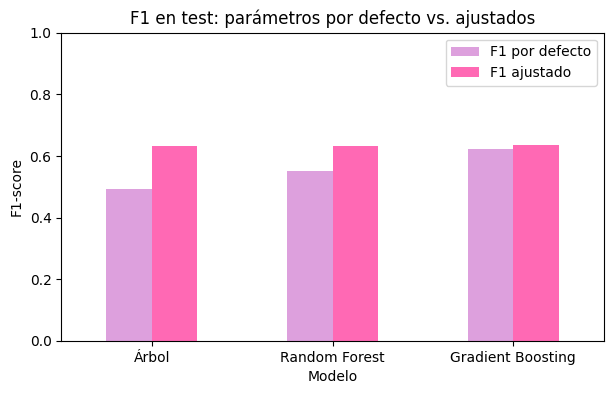

,F1 por defecto,F1 ajustado,Mejora
Modelo,,,
Árbol,0.491,0.631,0.140
Random Forest,0.550,0.631,0.082
Gradient Boosting,0.622,0.635,0.013


In [52]:
arbol_defecto = Pipeline([
    ("preprocesamiento", pipeline10),
    ("clasificador", DecisionTreeClassifier(class_weight="balanced", random_state=42)),
])
rf_defecto = Pipeline([
    ("preprocesamiento", pipeline10),
    ("clasificador", RandomForestClassifier(class_weight="balanced", random_state=42)),
])
gb_defecto = ImbPipeline(pipeline10.steps + [
    ("muestreo", RandomOverSampler(random_state=42)),
    ("clasificador", GradientBoostingClassifier(random_state=42)),
])

comparacion = []
for nombre, defecto, ajustado in [("Árbol", arbol_defecto, modelo_arbol),
                                  ("Random Forest", rf_defecto, modelo_rf),
                                  ("Gradient Boosting", gb_defecto, modelo_gb)]:
    defecto.fit(X_train, y_train)
    f1_defecto = f1_score(y_test, defecto.predict(X_test))
    f1_ajustado = f1_score(y_test, ajustado.predict(X_test))
    comparacion.append({"Modelo": nombre,
                        "F1 por defecto": f1_defecto,
                        "F1 ajustado": f1_ajustado,
                        "Mejora": f1_ajustado - f1_defecto})

comparacion = pd.DataFrame(comparacion).set_index("Modelo").round(3)

comparacion[["F1 por defecto", "F1 ajustado"]].plot(kind="bar", rot=0, color=["plum", "hotpink"], figsize=(7, 4))
plt.ylim(0, 1)
plt.ylabel("F1-score")
plt.title("F1 en test: parámetros por defecto vs. ajustados")
plt.show()

comparacion

Al ajustar los parámetros, los tres modelos mejoraron sus resultados:
- Árbol de decisión: mejoró más, pasando de 0,491 a 0,631 de F1. Al limitar su profundidad y aumentar el mínimo de clientes por hoja, se evitó que memorizara los datos.
- Random Forest: pasó de 0,550 a 0,631. Limitar la profundidad y aumentar el número de árboles permitió mejorar sus resultados.
- Gradient Boosting: mejoró ligeramente, de 0,622 a 0,635, porque sus parámetros por defecto ya ofrecían buenos resultados.

### 12. Interpreta y razona cada uno de los modelos empleados.


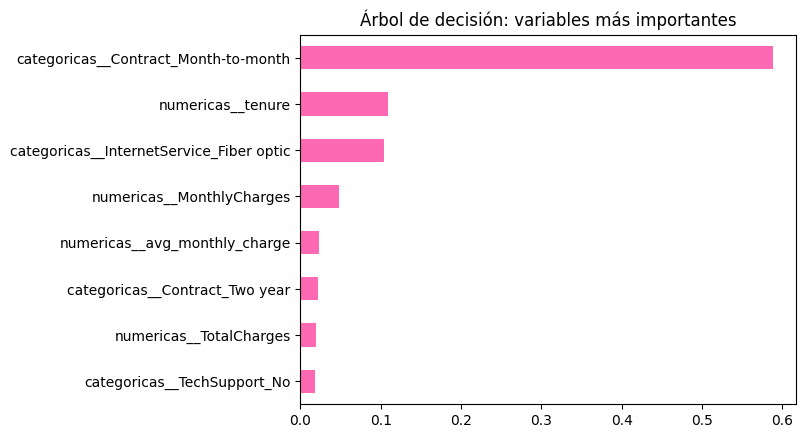

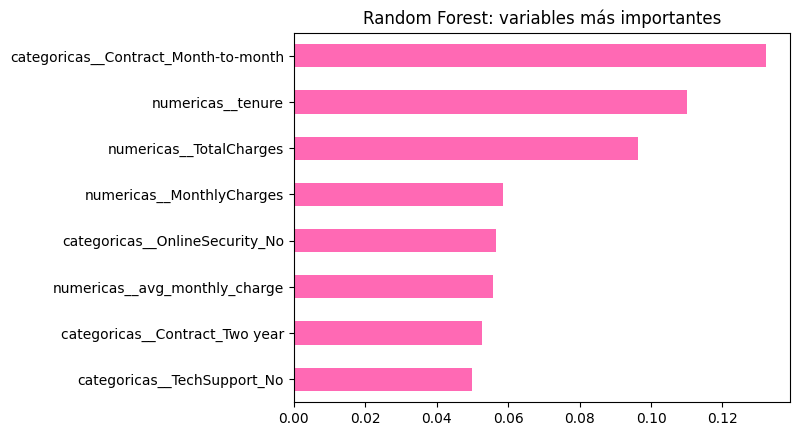

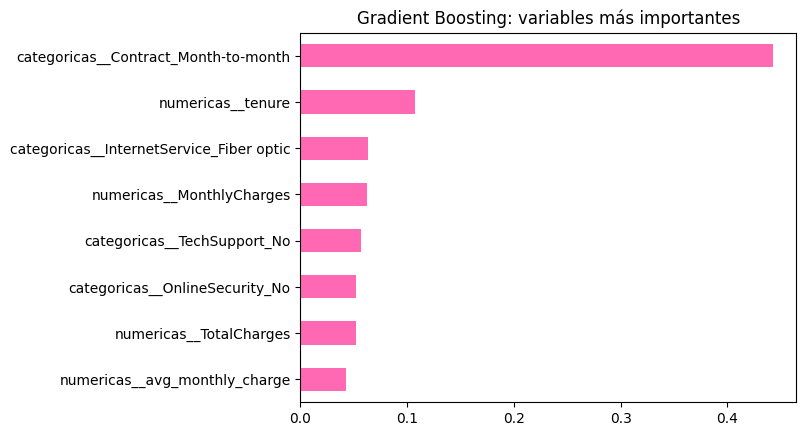

In [55]:
nombres = pipeline10.named_steps["preprocesado"].get_feature_names_out()

imp_arbol = pd.Series(modelo_arbol.named_steps["clasificador"].feature_importances_, index=nombres)
imp_arbol.nlargest(8).sort_values().plot(kind="barh", color="hotpink")
plt.title("Árbol de decisión: variables más importantes")
plt.show()

imp_rf = pd.Series(modelo_rf.named_steps["clasificador"].feature_importances_, index=nombres)
imp_rf.nlargest(8).sort_values().plot(kind="barh", color="hotpink")
plt.title("Random Forest: variables más importantes")
plt.show()

imp_gb = pd.Series(modelo_gb.named_steps["clasificador"].feature_importances_, index=nombres)
imp_gb.nlargest(8).sort_values().plot(kind="barh", color="hotpink")
plt.title("Gradient Boosting: variables más importantes")
plt.show()

Árbol de decisión

Es el modelo más fácil de interpretar porque funciona mediante reglas. La variable más importante es el contrato mes a mes (59 %). Después destacan la antigüedad del cliente (11 %) y tener fibra óptica (10 %).

Los clientes con contratos mensuales y poca antigüedad son los que presentan mayor riesgo de abandono.

Random Forest

Combina 600 árboles y realiza una votación para obtener la predicción final. Reparte más la importancia entre las variables, aunque el contrato mensual sigue siendo la más importante (13 %). También destacan la antigüedad, los cargos totales y la cuota mensual.

Es más estable, pero más difícil de interpretar que un árbol individual.

Gradient Boosting

Utiliza 200 árboles pequeños que van corrigiendo los errores de los anteriores. La variable más importante vuelve a ser el contrato mensual (44 %), seguida de la antigüedad y la fibra óptica.

Es el modelo que mejor detecta a los clientes que abandonan, con un recall de 0,805 y un AUC de 0,844.

Conclusiones comunes

Los tres modelos coinciden en que los clientes con mayor riesgo de abandono suelen tener:
- Contrato mes a mes.
- Poca antigüedad en la compañía.
- Fibra óptica y cuotas mensuales elevadas.
- Menos servicios adicionales, como soporte técnico o seguridad online.

### 13. Recomienda el modelo más apropiado para este caso y propón posibles mejoras.

Modelo recomendado: Gradient Boosting

Recomiendo Gradient Boosting porque obtiene los mejores resultados: el mayor F1 (0,635), el mayor recall (0,805) y el mejor AUC (0,844). Además, comete menos falsos negativos, algo importante porque interesa detectar a los clientes que van a abandonar.

Su principal desventaja es que es más difícil de interpretar. Si la empresa necesita entender fácilmente las decisiones, el árbol de decisión sería una buena alternativa, ya que ofrece resultados muy parecidos.

Posibles mejoras
1. Ajustar el umbral de decisión para detectar más clientes que abandonan.
2. Utilizar GridSearchCV para probar más combinaciones de parámetros.
3. Añadir nuevas variables, como quejas o llamadas al servicio técnico.
4. Eliminar variables poco útiles o repetidas.
5. Probar otros modelos como XGBoost o LightGBM.
6. Comprobar si las diferencias entre modelos son realmente significativas.
7. Actualizar y entrenar el modelo periódicamente con datos nuevos.